In [1]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
file_path = "/home/dbtproject/barsha/LLM/Gemini_old.csv"

df = pd.read_csv(file_path)
df = df.replace("M_ graminicola", "M_Graminicola")
df = df.replace("M_ incognita","M_Incognita")
df = df.replace("M_ javanica", "M_Javanica")
df = df.replace("M_graminicola", "M_Graminicola")
df = df.replace("M_incognita","M_Incognita")
print(df.head(20))

        img_name original_class predicted_class
0     test_img_1  M_Graminicola      M_Javanica
1     test_img_2  M_Graminicola   M_Graminicola
2     test_img_3  M_Graminicola   M_Graminicola
3     test_img_4  M_Graminicola      M_Javanica
4     test_img_5  M_Graminicola   M_Graminicola
5     test_img_6  M_Graminicola   M_Graminicola
6     test_img_7  M_Graminicola     M_Incognita
7     test_img_8  M_Graminicola      M_Javanica
8     test_img_9  M_Graminicola   M_Graminicola
9    test_img_10  M_Graminicola      M_Javanica
10   test_img_31  M_Graminicola   M_Graminicola
11   test_img_32  M_Graminicola     M_Incognita
12   test_img_33  M_Graminicola   M_Graminicola
13   test_img_34  M_Graminicola      M_Javanica
14   test_img_35  M_Graminicola      M_Javanica
15   test_img_36  M_Graminicola     M_Incognita
16   test_img_37  M_Graminicola      M_Javanica
17   test_img_38  M_Graminicola   M_Graminicola
18   test_img_39  M_Graminicola     M_Incognita
19   test_img_40  M_Graminicola      M_J

In [3]:
y_true = df["original_class"]
y_pred = df["predicted_class"]

In [4]:
accuracy = accuracy_score(y_true, y_pred)

print("Accuracy:", round(accuracy*100, 2), "%")

Accuracy: 43.33 %


In [5]:
precision = precision_score(
    y_true,
    y_pred,
    average='macro'
)

print("Precision:", round(precision,4))

Precision: 0.435


In [6]:
recall = recall_score(
    y_true,
    y_pred,
    average='macro'
)

print("Recall:", round(recall,4))

Recall: 0.4333


In [7]:
f1 = f1_score(
    y_true,
    y_pred,
    average='macro'
)

print("F1 Score:", round(f1,4))

F1 Score: 0.4294


In [8]:
report = classification_report(
    y_true,
    y_pred,
    digits =4
)

print(report)

               precision    recall  f1-score   support

M_Graminicola     0.4444    0.4000    0.4211        20
  M_Incognita     0.4375    0.3500    0.3889        20
   M_Javanica     0.4231    0.5500    0.4783        20

     accuracy                         0.4333        60
    macro avg     0.4350    0.4333    0.4294        60
 weighted avg     0.4350    0.4333    0.4294        60



In [9]:
cm = confusion_matrix(y_true, y_pred)

print(cm)

[[ 8  4  8]
 [ 6  7  7]
 [ 4  5 11]]


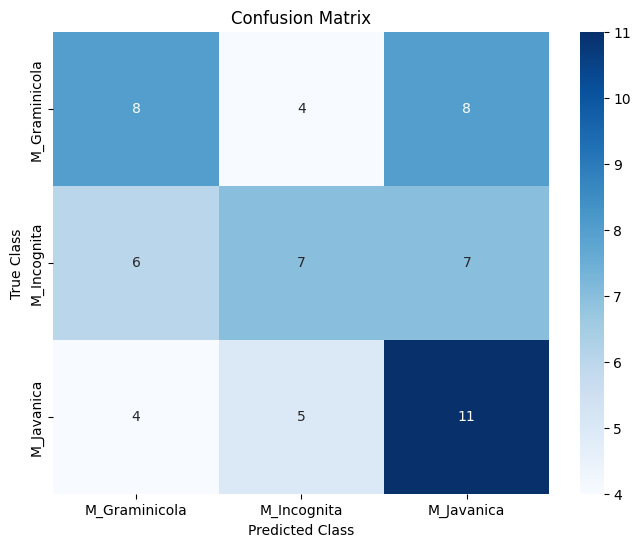

In [10]:
labels = sorted(df["original_class"].unique())

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")

plt.show()

In [11]:
import numpy as np

print("Unique true labels:", np.unique(y_true))
print("Unique predicted labels:", np.unique(y_pred))

Unique true labels: ['M_Graminicola' 'M_Incognita' 'M_Javanica']
Unique predicted labels: ['M_Graminicola' 'M_Incognita' 'M_Javanica']
